# Aai-Food Delivery × Open Knowledge Format (OKF)

Aai-Food delivers food in Pune, Mumbai and Bengaluru. We have one month of their orders (October 2026) in Postgres.

The plan for this notebook:

1. Ask an AI agent a business question with nothing but the database schema.
2. Ask the same question again, this time with an OKF bundle it can read.
3. Check both answers against SQL we wrote by hand.

## 1. Setup

In [ ]:
import os

import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from sqlalchemy import URL, create_engine, text

# DB login + Groq API key come from .env
load_dotenv()

# don't truncate long SQL / answers in the tables
pd.set_option("display.max_colwidth", None)

# quick check that Postgres is up
admin_url = URL.create(
    "postgresql+psycopg2",
    username=os.getenv("PG_USER"),
    password=os.getenv("PG_PASSWORD"),
    host=os.getenv("PG_HOST", "localhost"),
    port=int(os.getenv("PG_PORT", "5432")),
    database="postgres",
)
with create_engine(admin_url).connect() as conn:
    version = conn.execute(text("SELECT version()")).scalar()

print("Connected to", version.split(",")[0])
print("LLM:", os.getenv("LLM_MODEL", "openai/gpt-oss-120b"))

## 2. Load the data
This creates the `aai_food` database with two tables, `restaurants` and `orders`.
It also creates a read-only user, `okf_reader`. The AI agents only ever connect as that user.

In [31]:
from scripts.ingest_data import main as ingest_data

ingest_data()

Database 'aai_food' created
Tables restaurants and orders created
Loaded 18 rows into restaurants
Loaded 734 rows into orders
Indexes created on orders(city, order_placed_at, restaurant_id)
Read-only role 'okf_reader' ready (SELECT on restaurants, orders)

Summary
  restaurants    18 rows
  orders        734 rows

  Orders by status
  Cancelled      25
  Delivered     709


In [32]:
# all the helpers for this demo live in okf_agent.py
import okf_agent as okf
from okf_agent import run_sql   # SELECT query in, DataFrame out

print("restaurants")
display(run_sql("SELECT * FROM restaurants LIMIT 5"))
print("orders")
display(run_sql("SELECT * FROM orders LIMIT 5"))

restaurants


,restaurant_id,restaurant_name,cuisine,city,area,rating,avg_prep_time_min,is_active,joined_on
0,R001,Shree Krishna Vada Pav,Street Food,Pune,Kothrud,4.4,10,True,2024-02-11
1,R002,Biryani Darbar,Biryani,Pune,Koregaon Park,4.5,22,True,2023-08-19
2,R003,Puneri Misal House,Maharashtrian,Pune,Shivajinagar,4.6,14,True,2024-05-02
3,R004,Green Bowl Salads,Healthy,Pune,Baner,4.2,12,True,2025-01-15
4,R005,Dragon Wok,Chinese,Pune,Viman Nagar,4.0,18,True,2024-11-23


orders


,order_id,customer_id,restaurant_id,city,order_placed_at,order_delivered_at,status,order_value_inr,delivery_fee_inr,discount_inr,payment_method,rider_id,distance_km,weather,customer_rating
0,ORD100001,CUST0080,R012,Mumbai,2026-10-01 09:52:35,2026-10-01 10:16:35,Delivered,158,35,0,UPI,RD036,6.0,Clear,5
1,ORD100002,CUST0084,R008,Mumbai,2026-10-01 11:14:49,2026-10-01 11:39:49,Delivered,503,0,75,UPI,RD024,1.6,Clear,5
2,ORD100003,CUST0371,R008,Mumbai,2026-10-01 11:40:03,2026-10-01 12:18:03,Delivered,472,30,30,Wallet,RD009,7.8,Clear,4
3,ORD100004,CUST0305,R018,Bengaluru,2026-10-01 12:32:05,2026-10-01 12:50:05,Delivered,210,40,0,UPI,RD038,1.5,Clear,4
4,ORD100005,CUST0353,R006,Pune,2026-10-01 13:59:43,2026-10-01 14:39:43,Delivered,623,0,0,Cash on Delivery,RD041,5.6,Clear,5


In [33]:
run_sql("""
    SELECT 'restaurants' AS table_name, COUNT(*) AS rows FROM restaurants
    UNION ALL
    SELECT 'orders', COUNT(*) FROM orders
""")

,table_name,rows
0,restaurants,18
1,orders,734


Quick look at how the orders split up. Keep an eye on `status`: some orders were cancelled, and that matters later.

In [34]:
for column in ["city", "status", "weather"]:
    df = run_sql(f"SELECT {column}, COUNT(*) AS orders FROM orders GROUP BY {column} ORDER BY orders DESC")
    print(df.to_markdown(index=False), end="\n\n")

| city      |   orders |
|:----------|---------:|
| Pune      |      345 |
| Mumbai    |      246 |
| Bengaluru |      143 |

| status    |   orders |
|:----------|---------:|
| Delivered |      709 |
| Cancelled |       25 |

| weather    |   orders |
|:-----------|---------:|
| Clear      |      658 |
| Rain       |       46 |
| Heavy Rain |       30 |



## 3. The questions
Here's the setup we're testing. Both agents use the same LLM, the same database and the same code. The only difference is what the LLM gets to read before it writes SQL.

![One question, two agents](images/01_overview.png)

We'll go through question 1 slowly, one step per cell. After that, questions 2 to 5 run in a loop.

In [35]:
QUESTIONS = [
    "What was the average delivery time in each city in October 2026?",
    "What percentage of deliveries were late in Pune?",
    "Why were deliveries so slow in Pune last Friday?",
    "Which 5 restaurants had the highest late delivery rate? Show restaurant name and city.",
    "What was our net revenue in Mumbai in October 2026?",
]

# answers get collected here by question number (1-5) for the comparison at the end
results_without = {}
results_with = {}
ground_truth = {}

question = QUESTIONS[0]
question

'What was the average delivery time in each city in October 2026?'

## 4. Question 1 without OKF

![Question 1 without OKF](images/02_without_okf.png)

### Step 1: what the agent gets
Just the table and column names from the database. Nothing about what a column *means*.

In [37]:
schema = okf.schema_only()
print(schema)

print("\nSystem prompt:", okf.BASELINE_SYSTEM)

Database tables:
- orders: order_id (text), customer_id (text), restaurant_id (text), city (text), order_placed_at (timestamp without time zone), order_delivered_at (timestamp without time zone), status (text), order_value_inr (integer), delivery_fee_inr (integer), discount_inr (integer), payment_method (text), rider_id (text), distance_km (numeric), weather (text), customer_rating (smallint)
- restaurants: restaurant_id (text), restaurant_name (text), cuisine (text), city (text), area (text), rating (numeric), avg_prep_time_min (integer), is_active (boolean), joined_on (date)

System prompt: You are a data analyst for a food delivery company. You query a PostgreSQL database.


### Step 2: the LLM writes SQL

In [38]:
sql_without = okf.write_sql(question, okf.BASELINE_SYSTEM, schema)
print(sql_without)

SELECT
    city,
    ROUND(AVG(EXTRACT(EPOCH FROM (order_delivered_at - order_placed_at)) / 60)::numeric, 2) AS avg_delivery_time_minutes
FROM
    orders
WHERE
    order_placed_at >= DATE '2026-10-01'
    AND order_placed_at <  DATE '2026-11-01'
    AND order_delivered_at IS NOT NULL
    AND status = 'delivered'
GROUP BY
    city
ORDER BY
    city;


Look at the `WHERE` clause. Did it filter on `status`? Nothing in the schema says it should.

### Step 3: run it

In [39]:
df_without = run_sql(sql_without)
df_without

,city,avg_delivery_time_minutes


### Step 4: turn the result into an answer
The LLM gets the question, its own SQL and the result table, and writes a few sentences.

In [40]:
answer_without = okf.write_answer(question, okf.BASELINE_SYSTEM, sql_without, df_without)
print(answer_without)

results_without[1] = {"answer": answer_without, "files_used": []}

The query didn’t return any rows, which means there were no orders that met all of the criteria (placed in October 2026, marked ‘delivered’, with a non‑null delivery timestamp) for any city. In other words, we don’t have any recorded delivery times to calculate an average for October 2026. If you think deliveries should exist for that period, you may want to verify that the `order_placed_at`, `order_delivered_at`, and `status` fields are being populated correctly, or broaden the date range to include a wider window. Let me know if you’d like me to run a revised query.


## 5. The OKF bundle
This is what the second agent gets to read: a folder of markdown files in `okf/aai-food/`.

In [41]:
def print_tree(folder, indent=""):
    for item in sorted(folder.iterdir(), key=lambda p: (p.is_file(), p.name)):
        print(f"{indent}{'📁' if item.is_dir() else '📄'} {item.name}")
        if item.is_dir():
            print_tree(item, indent + "    ")

print(f"📁 {okf.BUNDLE_PATH.name}/")
print_tree(okf.BUNDLE_PATH, "    ")

📁 aai-food/
    📁 glossary
        📄 business_terms.md
        📄 index.md
    📁 metrics
        📄 delivery_time.md
        📄 index.md
        📄 late_delivery_rate.md
        📄 net_revenue.md
    📁 playbooks
        📄 heavy_rain.md
        📄 index.md
    📁 tables
        📄 index.md
        📄 orders.md
        📄 restaurants.md
    📄 index.md
    📄 log.md


Before an agent uses the bundle, we check it: every file needs a `type` in its front matter, and every link has to point to a file that exists.

In [42]:
concepts = okf.load_bundle()               # one entry per .md file
problems = okf.validate_bundle(concepts)   # [] means all good

print(f"{len(concepts)} files")
print(pd.Series([c["type"] for c in concepts]).value_counts().to_string(), end="\n\n")
print("Bundle is valid" if not problems else "Problems:\n" + "\n".join(problems))

13 files
Index               5
Metric              3
PostgreSQL Table    2
Glossary            1
Log                 1
Playbook            1

Bundle is valid


The same files drawn as a graph. Each arrow is a markdown link from one file to another.

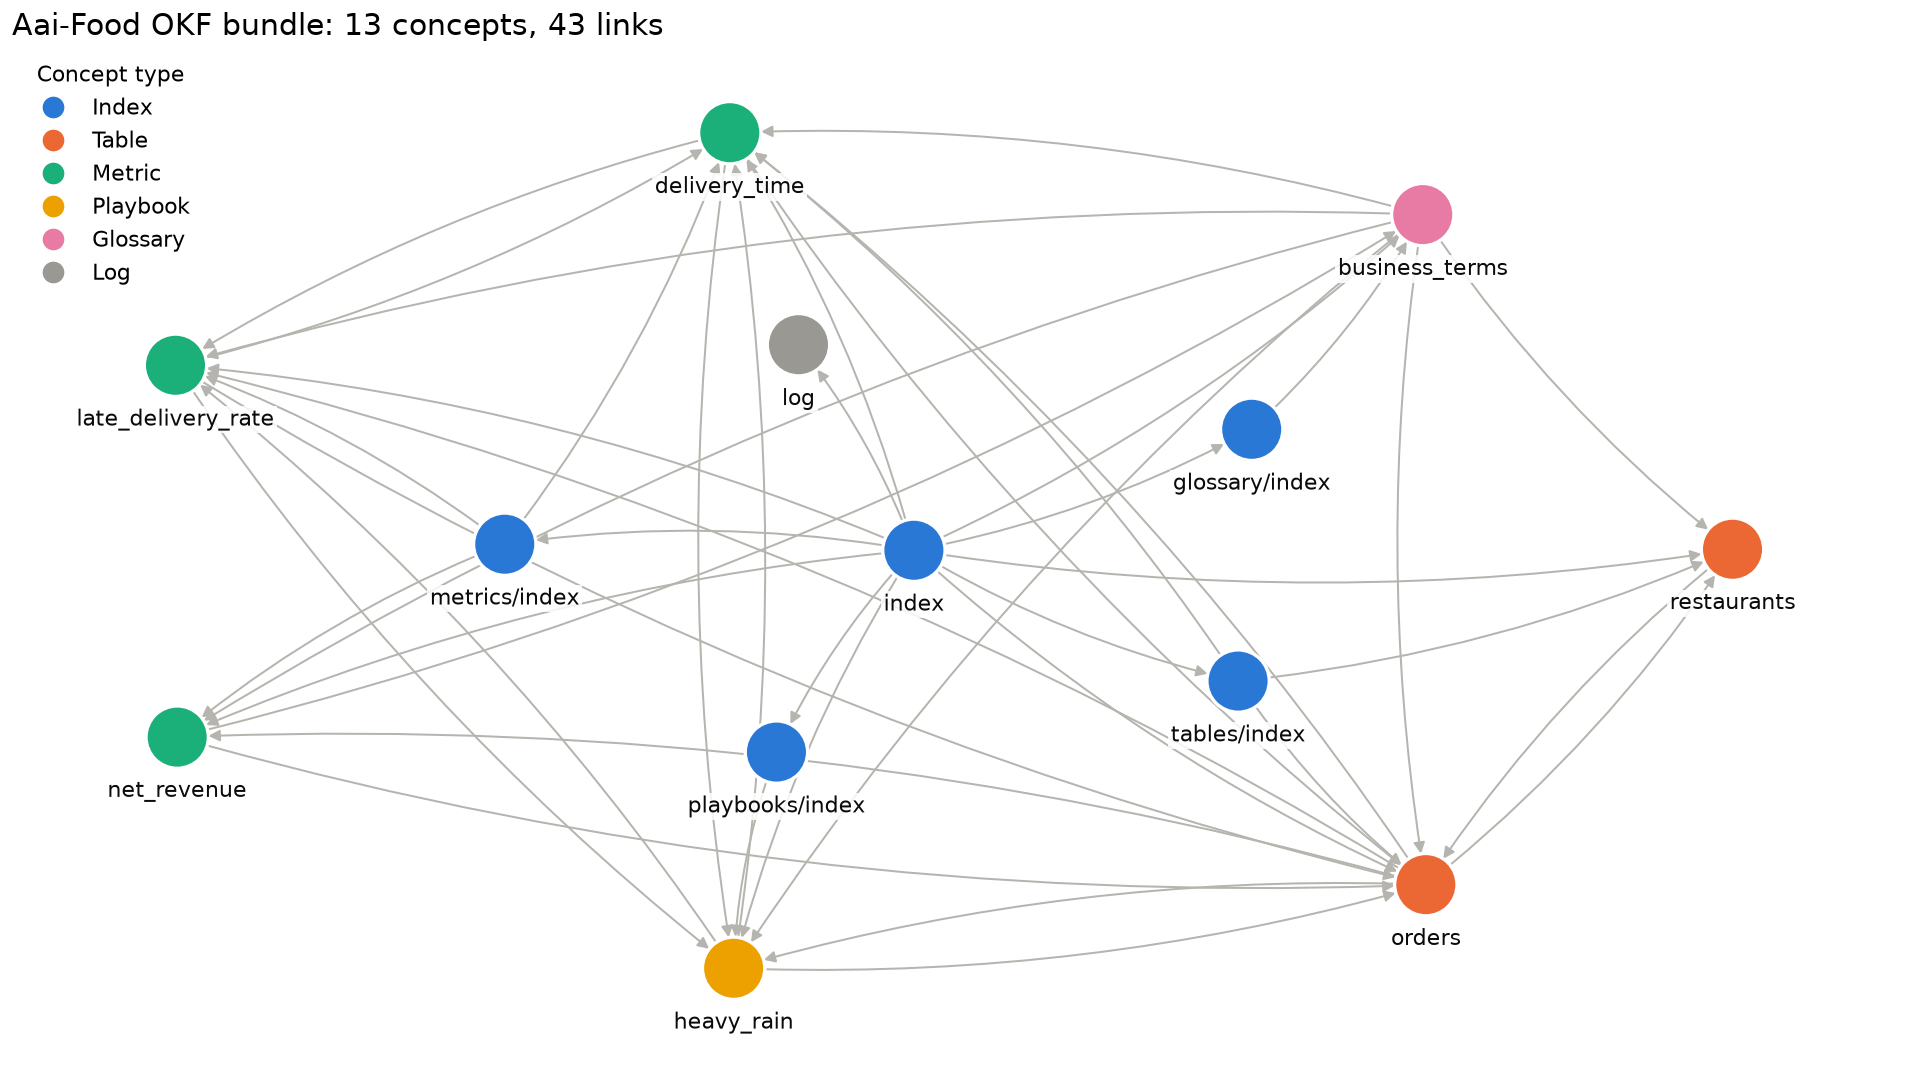

In [43]:
G = okf.build_graph(concepts)
okf.draw_graph(G)

## 6. Question 1 with OKF

![Question 1 with OKF](images/03_with_okf.png)

### Step 1: start with the index files
The agent doesn't load the whole bundle. It only reads these short table-of-contents files first.

In [44]:
for name in okf.index_files():
    print(name)

index.md
glossary/index.md
metrics/index.md
playbooks/index.md
tables/index.md


### Step 2: the LLM picks what to read
It sees the question plus the index files, and replies with up to 3 file paths.

In [45]:
files_used = okf.select_concepts(question)

📂 OKF files chosen: tables/orders.md, tables/restaurants.md, metrics/delivery_time.md


### Step 3: read those files
Their full text goes into the prompt, where the schema went last time.

In [46]:
knowledge = okf.read_concepts(files_used)
print(f"{len(files_used)} files, {len(knowledge):,} characters")

print("\nSystem prompt:", okf.OKF_SYSTEM)

3 files, 7,830 characters

System prompt: You are a data analyst for Aai-Food Delivery. You query a PostgreSQL database. The OKF knowledge files below are the source of truth: follow their definitions, filters, allowed values and reporting rules exactly.


### Step 4: the LLM writes SQL
Same `write_sql` function as in section 4. The only thing passed in differently is `knowledge` instead of `schema`.

In [47]:
sql_with = okf.write_sql(question, okf.OKF_SYSTEM, knowledge)
print(sql_with)

SELECT
    city,
    ROUND(
        AVG(EXTRACT(EPOCH FROM (order_delivered_at - order_placed_at)) / 60.0)::numeric,
        1
    ) AS avg_delivery_min
FROM orders
WHERE status = 'Delivered'
  AND order_placed_at >= '2026-10-01'
  AND order_placed_at <  '2026-11-01'
GROUP BY city
ORDER BY city;


Compare this `WHERE` clause with the one from section 4.

### Step 5: run it

In [48]:
df_with = run_sql(sql_with)
df_with

,city,avg_delivery_min
0,Bengaluru,29.2
1,Mumbai,29.2
2,Pune,30.8


### Step 6: the answer
This time it also lists the files it relied on.

In [49]:
answer_with = okf.write_answer(question, okf.OKF_SYSTEM, sql_with, df_with, files_used)
print(answer_with)

results_with[1] = {"answer": answer_with, "files_used": files_used}

In October 2026, the average delivery time was very similar across the three cities we serve: Bengaluru and Mumbai each recorded an average of **29.2 minutes**, while Pune was slightly higher at **30.8 minutes**. All three cities stayed close to the 30‑minute benchmark for on‑time deliveries.  

Sources: tables/orders.md, tables/restaurants.md, metrics/delivery_time.md


## 7. Question 1: the right answer
SQL written by hand, following the rules in `metrics/delivery_time.md`: delivered orders only, time in minutes, rounded to 1 decimal.

In [50]:
# minutes between placing and receiving the order
DELIVERY_MIN = "EXTRACT(EPOCH FROM (order_delivered_at - order_placed_at)) / 60.0"

ground_truth_sql = {
    1: f"""
        SELECT city, ROUND(AVG({DELIVERY_MIN})::numeric, 1) AS avg_delivery_min
        FROM orders
        WHERE status = 'Delivered'
          AND order_placed_at >= '2026-10-01' AND order_placed_at < '2026-11-01'
        GROUP BY city ORDER BY city""",
}

ground_truth[1] = run_sql(ground_truth_sql[1])
ground_truth[1]

,city,avg_delivery_min
0,Bengaluru,29.2
1,Mumbai,29.2
2,Pune,30.8


Now all three side by side. The ground truth column is the raw query output. The AI answers are written in sentences, so the wording and rounding won't match exactly. Compare the numbers. The answer with OKF ends with the files it used.

In [51]:
import markdown
from IPython.display import HTML

def compare(numbers):
    """One row per question: the right answer next to both AI answers."""
    rows = ""
    for n in numbers:
        truth = ground_truth[n].to_html(index=False, border=0)
        # the AI answers are written in markdown (bold, small tables), so render them
        without = markdown.markdown(results_without[n]["answer"], extensions=["tables"])
        with_okf = markdown.markdown(results_with[n]["answer"], extensions=["tables"])
        rows += f"<tr><td><b>Q{n}.</b> {QUESTIONS[n - 1]}</td><td>{truth}</td><td>{without}</td><td>{with_okf}</td></tr>"

    style = """
    <style>
      .cmp { border-collapse: collapse; width: 100%; font-size: 13px; }
      .cmp > thead th { text-align: left; padding: 8px; border-bottom: 2px solid rgba(128,128,128,.6); }
      .cmp > tbody > tr > td { text-align: left; vertical-align: top; padding: 8px;
                               border-bottom: 1px solid rgba(128,128,128,.35); }
      .cmp td table { border-collapse: collapse; font-size: 12px; }
      .cmp td table th, .cmp td table td { padding: 2px 8px; text-align: left;
                                           border-bottom: 1px solid rgba(128,128,128,.25); }
      .cmp td p { margin: 0 0 6px 0; }
    </style>"""
    header = ("<thead><tr><th style='width:16%'>Question</th><th style='width:28%'>Ground truth (SQL output)</th>"
              "<th style='width:28%'>Without OKF</th><th style='width:28%'>With OKF</th></tr></thead>")
    return HTML(f"{style}<table class='cmp'>{header}<tbody>{rows}</tbody></table>")

compare([1])

## 8. Questions 2 to 5
No more step by step. `ask_without_okf()` and `ask_with_okf()` run the exact steps from sections 4 and 6 in a single call, and print the SQL, the result and the answer.

If Groq hits its rate limit, the helper waits 20 seconds and tries again, so this cell can take a minute or two.

In [52]:
for number in range(2, len(QUESTIONS) + 1):
    q = QUESTIONS[number - 1]

    print("=" * 100, f"\nQ{number} WITHOUT OKF")
    results_without[number] = okf.ask_without_okf(q)

    print("-" * 100, f"\nQ{number} WITH OKF")
    results_with[number] = okf.ask_with_okf(q)

Q2 WITHOUT OKF
❓ What percentage of deliveries were late in Pune?

🧾 SQL:
SELECT
    ROUND(
        100.0 * SUM(CASE 
                       WHEN order_delivered_at > order_placed_at + INTERVAL '30 minutes' 
                       THEN 1 
                       ELSE 0 
                   END) 
        / COUNT(*),
        2
    ) AS late_delivery_percentage
FROM orders
WHERE city = 'Pune'
  AND status = 'delivered';

| late_delivery_percentage   |
|:---------------------------|
|                            |

💬 Based on the data we have, there are **no delivered orders recorded for Pune** (the query returned a null/empty result). Because there’s no denominator to calculate a percentage, we can’t compute a late‑delivery rate for that city at this time. If you expect deliveries to be present, we may need to check the data load window or the filters (e.g., status, date range) to ensure the relevant orders are included. Let me know if you’d like me to adjust the query or investigate further

And the hand-written SQL for those four questions.

In [53]:
# "late" = delivered in more than 40 minutes (metrics/late_delivery_rate.md)
LATE = f"{DELIVERY_MIN} > 40"

ground_truth_sql.update({
    # Q2: late rate in Pune
    2: f"""
        SELECT COUNT(*) AS delivered,
               COUNT(*) FILTER (WHERE {LATE}) AS late,
               ROUND(100.0 * COUNT(*) FILTER (WHERE {LATE}) / COUNT(*), 1) AS late_rate_pct
        FROM orders
        WHERE status = 'Delivered' AND city = 'Pune'""",

    # Q3: "last Friday" = 30 Oct 2026 (today is Mon 2 Nov). Split by weather to see what happened.
    3: f"""
        SELECT weather,
               COUNT(*) FILTER (WHERE status = 'Delivered') AS delivered,
               COUNT(*) FILTER (WHERE status = 'Cancelled') AS cancelled,
               ROUND(AVG({DELIVERY_MIN}) FILTER (WHERE status = 'Delivered')::numeric, 1) AS avg_delivery_min,
               ROUND(100.0 * COUNT(*) FILTER (WHERE status = 'Delivered' AND {LATE})
                     / NULLIF(COUNT(*) FILTER (WHERE status = 'Delivered'), 0), 1) AS late_rate_pct
        FROM orders
        WHERE city = 'Pune' AND order_placed_at >= '2026-10-30' AND order_placed_at < '2026-10-31'
        GROUP BY weather ORDER BY avg_delivery_min""",

    # Q4: top 5 restaurants by late rate
    4: f"""
        SELECT r.restaurant_name, r.city, COUNT(*) AS delivered,
               COUNT(*) FILTER (WHERE {LATE}) AS late,
               ROUND(100.0 * COUNT(*) FILTER (WHERE {LATE}) / COUNT(*), 1) AS late_rate_pct
        FROM orders o
        JOIN restaurants r ON r.restaurant_id = o.restaurant_id
        WHERE o.status = 'Delivered'
        GROUP BY r.restaurant_name, r.city
        ORDER BY late_rate_pct DESC, late DESC
        LIMIT 5""",

    # Q5: net revenue = order value - discount + delivery fee (gmv shown alongside for contrast)
    5: """
        SELECT SUM(order_value_inr - discount_inr + delivery_fee_inr) AS net_revenue_inr,
               SUM(order_value_inr) AS gmv_inr
        FROM orders
        WHERE status = 'Delivered' AND city = 'Mumbai'
          AND order_placed_at >= '2026-10-01' AND order_placed_at < '2026-11-01'""",
})

for number in range(2, len(QUESTIONS) + 1):
    ground_truth[number] = run_sql(ground_truth_sql[number])
    print(f"Q{number}. {QUESTIONS[number - 1]}")
    print(ground_truth[number].to_markdown(index=False, floatfmt=".1f"), end="\n\n")

Q2. What percentage of deliveries were late in Pune?
|   delivered |   late |   late_rate_pct |
|------------:|-------:|----------------:|
|         331 |     42 |            12.7 |

Q3. Why were deliveries so slow in Pune last Friday?
| weather    |   delivered |   cancelled |   avg_delivery_min |   late_rate_pct |
|:-----------|------------:|------------:|-------------------:|----------------:|
| Heavy Rain |          25 |           5 |               49.9 |            92.0 |

Q4. Which 5 restaurants had the highest late delivery rate? Show restaurant name and city.
| restaurant_name       | city      |   delivered |   late |   late_rate_pct |
|:----------------------|:----------|------------:|-------:|----------------:|
| Annapurna Thali       | Pune      |          46 |     13 |            28.3 |
| Tandoori Nights       | Mumbai    |          43 |     11 |            25.6 |
| Meghana Style Biryani | Bengaluru |          28 |      6 |            21.4 |
| Biryani Darbar        | Pune 

## 9. Everything side by side
All five questions: the right answer, the agent without OKF, and the agent with OKF.

In [54]:
compare(range(1, len(QUESTIONS) + 1))

## 10. Changing a rule
Say the team decides a late rate should always be reported with its counts. We add that to `metrics/late_delivery_rate.md`, note it in `log.md`, and ask question 2 again.

![Changing a rule](images/04_update_knowledge.png)

The cell puts both files back the way they were when it finishes.

In [55]:
late_file = okf.BUNDLE_PATH / "metrics" / "late_delivery_rate.md"
log_file = okf.BUNDLE_PATH / "log.md"

original_late = late_file.read_text(encoding="utf-8")
original_log = log_file.read_text(encoding="utf-8")

team_note = """
# Team note (added 2026-11-02)

When reporting a late delivery rate, ALWAYS show it together with the counts,
for example: "12.3% (45 late out of 366 delivered orders)".
"""

try:
    late_file.write_text(original_late + team_note, encoding="utf-8")
    log_file.write_text(original_log + "- 2026-11-02: late_delivery_rate.md: added team note "
                        "(always show late and delivered counts with the rate).\n", encoding="utf-8")
    print("Team note added to metrics/late_delivery_rate.md, change logged in log.md\n")

    # same question, same code
    updated = okf.ask_with_okf(QUESTIONS[1])
finally:
    late_file.write_text(original_late, encoding="utf-8")
    log_file.write_text(original_log, encoding="utf-8")
    print("Both files restored")

Team note added to metrics/late_delivery_rate.md, change logged in log.md

📂 OKF files chosen: metrics/late_delivery_rate.md, tables/orders.md, tables/restaurants.md
❓ What percentage of deliveries were late in Pune?
📂 Files used: metrics/late_delivery_rate.md, tables/orders.md, tables/restaurants.md

🧾 SQL:
SELECT 
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE EXTRACT(EPOCH FROM (order_delivered_at - order_placed_at)) / 60.0 > 40
        ) / COUNT(*),
        1
    ) AS late_rate_pct,
    COUNT(*) FILTER (
        WHERE EXTRACT(EPOCH FROM (order_delivered_at - order_placed_at)) / 60.0 > 40
    ) AS late_orders,
    COUNT(*) AS delivered_orders
FROM orders
WHERE status = 'Delivered'
  AND city = 'Pune';

|   late_rate_pct |   late_orders |   delivered_orders |
|----------------:|--------------:|-------------------:|
|            12.7 |            42 |                331 |

💬 In Pune, 12.7 % of all delivered orders arrived later than the 40‑minute target, which correspo

## 11. Wrap up

- Same model, same code, different answers. Without the bundle, the agent had to guess what "delivered", "late" and "revenue" mean.
- The bundle is just markdown files with a bit of front matter. You can open them, review them and keep them in git.
- The agent only read the index files plus the 2-3 files it needed, not the whole bundle.
- Changing a rule meant editing one markdown file. `okf_agent.py` didn't change.